# Hyperparameter using Keras's tuner

In [9]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)


/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [13]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.


2026-04-04 19:25:22.951325: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-04-04 19:25:22.951384: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-04 19:25:22.951388: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-04-04 19:25:22.951992: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-04 19:25:22.952019: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


In [14]:
class_names = train_ds.class_names

print(f"Class mapping: {class_names}")

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class mapping: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [16]:
for images, labels in train_ds.take(1):
    print(f"Image batch shape: {images.shape}") # (BATCH_SIZE, 224, 224, 3)
    print(f"Label batch shape: {labels.shape}") # (32, 4)
    
    # Access the very first image in that batch
    first_image = images[0].numpy().astype("uint8")
    first_label = labels[0].numpy()

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 4)


2026-04-04 19:26:22.898556: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [17]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.2),
    
])

In [20]:
def build_model(hp):
    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(224, 224, 3)),
        
        # First conv2D Block
        layers.Conv2D(
            filters=hp.Int('conv_1_filter', min_value=16, max_value=64, step=16),
            kernel_size=(3, 3), 
            activation='relu'
        ),
        layers.MaxPooling2D((2, 2)),
        
        # Second conv2D Block
        layers.Conv2D(
            filters=hp.Int('conv_2_filter', min_value=32, max_value=128, step=32),
            kernel_size=(3, 3), 
            activation='relu'
        ),
        layers.MaxPooling2D((2, 2)),
        
        # Third conv2D Block
        layers.Conv2D(
            filters=hp.Int('conv_3_filter', min_value=64, max_value=256, step=64),
            kernel_size=(3, 3), 
            activation='relu'
        ),
        layers.MaxPooling2D((2, 2)),
        
        # Flatten
        layers.Flatten(),
        layers.Dense(
            units=hp.Int('dense_1_units', min_value=64, max_value=256, step=64),
            activation='relu'
        ),
        # Dropout rate
        layers.Dropout(rate=hp.Float('dropout_rate', min_value=0.2, max_value=0.6, step=0.1)),
        
        layers.Dense(4, activation='softmax')
    ])
    
    # Tune learning rate
    hp_lr = hp.Choice('learning_rate', values=[1e-3, 1e-4]) # Removed 1e-2 as it causes instability
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_lr),
        loss='categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

In [21]:
import keras_tuner as kt
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=10,
    directory='my_tuning_dir',
    project_name='CXC1_tuning'
)


stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

# Start the search
tuner.search(train_ds, validation_data=val_ds, epochs=10, callbacks=[stop_early])

Trial 7 Complete [00h 01m 48s]
val_accuracy: 0.9053876399993896

Best val_accuracy So Far: 0.9224704504013062
Total elapsed time: 00h 12m 04s

Search: Running Trial #8

Value             |Best Value So Far |Hyperparameter
48                |48                |conv_1_filter
32                |32                |conv_2_filter
128               |128               |conv_3_filter
256               |256               |dense_1_units
0.2               |0.5               |dropout_rate
0.001             |0.001             |learning_rate
2                 |2                 |tuner/epochs
0                 |0                 |tuner/initial_epoch
2                 |2                 |tuner/bracket
0                 |0                 |tuner/round

Epoch 1/2
208/408 ━━━━━━━━━━━━━━━━━━━━ 30s 152ms/step - accuracy: 0.5527 - loss: 1.3576

KeyboardInterrupt: 

In [22]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
final_model = tuner.hypermodel.build(best_hps)
final_model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
408/408 ━━━━━━━━━━━━━━━━━━━━ 63s 152ms/step - accuracy: 0.7580 - loss: 0.6797 - val_accuracy: 0.8909 - val_loss: 0.3658
Epoch 2/5
408/408 ━━━━━━━━━━━━━━━━━━━━ 62s 151ms/step - accuracy: 0.8405 - loss: 0.5223 - val_accuracy: 0.9028 - val_loss: 0.3414
Epoch 3/5
408/408 ━━━━━━━━━━━━━━━━━━━━ 61s 150ms/step - accuracy: 0.8660 - loss: 0.5168 - val_accuracy: 0.8857 - val_loss: 0.4092
Epoch 4/5
408/408 ━━━━━━━━━━━━━━━━━━━━ 62s 151ms/step - accuracy: 0.8682 - loss: 0.6056 - val_accuracy: 0.8620 - val_loss: 0.6809
Epoch 5/5
408/408 ━━━━━━━━━━━━━━━━━━━━ 62s 152ms/step - accuracy: 0.8519 - loss: 0.8457 - val_accuracy: 0.8817 - val_loss: 1.0294


In [23]:
# Save the model
final_model.save('CXC_tuner1.keras')
print("Model saved successfully!")

Model saved successfully!


In [24]:
final_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 48)   │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 48)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 32)   │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,613,934 (254.11 MB)

 Trainable params: 22,204,644 (84.70 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,409,290 (169.41 MB)

In [25]:
# Evaludate against test data
results = final_model.evaluate(train_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

408/408 ━━━━━━━━━━━━━━━━━━━━ 24s 59ms/step - accuracy: 0.8891 - loss: 0.5409
Test Loss: 0.5409291386604309
Test Accuracy: 88.91%


2026-02-26 23:21:22.699539: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


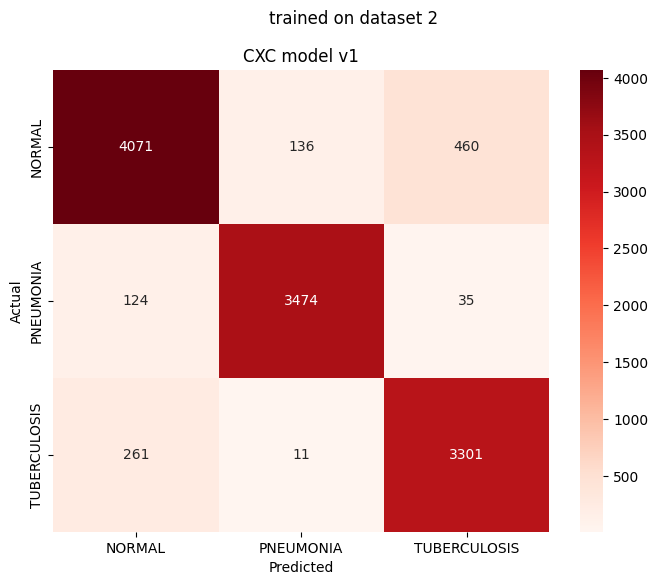

              precision    recall  f1-score   support

      NORMAL       0.91      0.87      0.89      4667
   PNEUMONIA       0.96      0.96      0.96      3633
TUBERCULOSIS       0.87      0.92      0.90      3573

    accuracy                           0.91     11873
   macro avg       0.91      0.92      0.92     11873
weighted avg       0.91      0.91      0.91     11873



In [34]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in train_ds:
    preds = final_model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [25]:
model_path = os.getenv("MODEL_DIR")
model = os.path.join(model_path, "CXC1.keras")
print(model)
model = tf.keras.models.load_model(model)


/Users/joshan/Documents/final-year-project/models/CXC/CXC1.keras


In [27]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8890 - loss: 5.5567
Test Loss: 5.556668758392334
Test Accuracy: 88.90%


In [36]:
final_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,736,331 (254.58 MB)

 Trainable params: 22,245,443 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 44,490,888 (169.72 MB)

In [ ]:
import numpy as np

predictions = model.predict(val_ds)

class_names = val_ds.class_names

file_paths = val_ds.file_paths

for i, pred in enumerate(predictions):
    confidence = np.max(pred)
    predicted_class = class_names[np.argmax(pred)]
    
    print(f"Image: {file_paths[i]}")
    print(f"Predicted: {predicted_class}")
    print(f"Confidence: {confidence:.4f}")
    print("-" * 50)

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/PNEUMONIA/person966_bacteria_2891.jpeg
Predicted: NORMAL
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/NORMAL/Normal-460.png
Predicted: NORMAL
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/PNEUMONIA/person501_bacteria_2116.jpeg
Predicted: NORMAL
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/TUBERCULOSIS/Tuberculosis-250.png
Predicted: NORMAL
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/NORMAL/Normal-3406.png
Predicted: TUBERCULOSIS
Confidence: 1.0000
--------------------------------------------------
Image: /User

In [68]:
for i, pred in enumerate(predictions):
    confidence = float(pred[0])
    
    if confidence > 0.5:
        predicted_class = "PNEUMONIA"
    else:
        predicted_class = "NORMAL"
        confidence = 1 - confidence
        
    print(f"Image: {file_paths[i]}")
    print(f"Predicted: {predicted_class}")
    print(f"Confidence: {confidence:.4f}")
    print("-" * 50)

Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/PNEUMONIA/person966_bacteria_2891.jpeg
Predicted: PNEUMONIA
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/NORMAL/Normal-460.png
Predicted: PNEUMONIA
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/PNEUMONIA/person501_bacteria_2116.jpeg
Predicted: PNEUMONIA
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/TUBERCULOSIS/Tuberculosis-250.png
Predicted: PNEUMONIA
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-project/dataset/data02/val/NORMAL/Normal-3406.png
Predicted: NORMAL
Confidence: 1.0000
--------------------------------------------------
Image: /Users/joshan/Documents/final-year-proj